In [2]:
import pandas as pd
import os

# Project data directory
DATA_PATH = "C:\\Users\\User\\Downloads\\Marketmind ai"

# Dataset files
files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

dataframes = {}

print("=" * 65)
print("          MARKETMIND AI - INITIAL DATA AUDIT")
print("=" * 65)

for name, filename in files.items():

    filepath = os.path.join(DATA_PATH, filename)

    df = pd.read_csv(filepath)

    dataframes[name] = df

    print(f"\nDATASET: {name.upper()}")
    print("-" * 50)

    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

    print("\nFirst 3 Records:")
    print(df.head(3))

print("\n" + "=" * 65)
print("INITIAL DATA AUDIT COMPLETED")
print("=" * 65)

          MARKETMIND AI - INITIAL DATA AUDIT

DATASET: CUSTOMERS
--------------------------------------------------
Shape: (99441, 5)

Columns:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Data Types:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

Missing Values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Duplicate Rows:
0

First 3 Records:
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   

   customer_zip_code_prefix          custom

In [3]:
import pandas as pd
import os

DATA_PATH = "C:\\Users\\User\\Downloads\\Marketmind ai"
OUTPUT_PATH = "C:\\Users\\User\\Downloads\\Marketmind ai\\processed"

os.makedirs(OUTPUT_PATH, exist_ok=True)

files = [
    "olist_customers_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "product_category_name_translation.csv"
]

report = []

for filename in files:

    df = pd.read_csv(os.path.join(DATA_PATH, filename))

    report.append({
        "Dataset": filename,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing_Values": df.isnull().sum().sum(),
        "Duplicate_Rows": df.duplicated().sum(),
        "Memory_MB": round(
            df.memory_usage(deep=True).sum() / (1024**2), 2
        )
    })

quality_df = pd.DataFrame(report)

quality_df.to_csv(
    os.path.join(OUTPUT_PATH, "data_quality_report.csv"),
    index=False
)

print("\nDATA QUALITY REPORT")
print(quality_df.to_string(index=False))

print("\nReport saved successfully!")


DATA QUALITY REPORT
                              Dataset    Rows  Columns  Missing_Values  Duplicate_Rows  Memory_MB
          olist_customers_dataset.csv   99441        5               0               0      26.59
             olist_orders_dataset.csv   99441        8            4908               0      52.94
        olist_order_items_dataset.csv  112650        7               0               0      35.99
     olist_order_payments_dataset.csv  103886        5               0               0      16.23
      olist_order_reviews_dataset.csv   99224        7          145903               0      39.12
           olist_products_dataset.csv   32951        9            2448               0       6.30
            olist_sellers_dataset.csv    3095        4               0               0       0.59
        olist_geolocation_dataset.csv 1000163        5               0          261831     130.26
product_category_name_translation.csv      71        2               0               0       0.01

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Paths
DATA_PATH = "C:\\Users\\User\\Downloads\\Marketmind ai"
OUTPUT_PATH = "C:\\Users\\User\\Downloads\\Marketmind ai\\processed"
PLOT_PATH = "C:\\Users\\User\\Downloads\\Marketmind ai\\reports"

os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(PLOT_PATH, exist_ok=True)

# Load datasets
customers = pd.read_csv( "C:\\Users\\User\\Downloads\\Marketmind ai\\olist_customers_dataset.csv")
orders = pd.read_csv("C:\\Users\\User\\Downloads\\Marketmind ai\\olist_orders_dataset.csv")
items = pd.read_csv("C:\\Users\\User\\Downloads\\Marketmind ai\\olist_order_items_dataset.csv")
payments = pd.read_csv("C:\\Users\\User\\Downloads\\Marketmind ai\\olist_order_payments_dataset.csv")
reviews = pd.read_csv("C:\\Users\\User\\Downloads\\Marketmind ai\\olist_order_reviews_dataset.csv")
products = pd.read_csv("C:\\Users\\User\\Downloads\\Marketmind ai\\olist_products_dataset.csv")
sellers = pd.read_csv("C:\\Users\\User\\Downloads\\Marketmind ai\\olist_sellers_dataset.csv")

In [7]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

In [8]:
# Calculate revenue for each order item
items["item_revenue"] = items["price"] + items["freight_value"]

# Aggregate revenue by order
order_revenue = (
    items.groupby("order_id")
    .agg(
        revenue=("item_revenue", "sum"),
        total_products=("order_item_id", "count")
    )
    .reset_index()
)

# Merge with order information
sales = orders.merge(order_revenue, on="order_id", how="left")

sales["revenue"] = sales["revenue"].fillna(0)

# Business KPIs
total_orders = sales["order_id"].nunique()

total_revenue = sales["revenue"].sum()

average_order_value = (
    total_revenue / total_orders if total_orders else 0
)

print("\n========== SALES KPIs ==========")

print("Total Orders:", total_orders)

print("Total GMV:", round(total_revenue, 2))

print("Average Order Value:", round(average_order_value, 2))

print("Order Status Distribution:")
print(sales["order_status"].value_counts())


========== SALES KPIs ==========
Total Orders: 99441
Total GMV: 15843553.24
Average Order Value: 159.33
Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [9]:
sales["purchase_month"] = (
    sales["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_sales = (
    sales.groupby("purchase_month")
    .agg(
        revenue=("revenue", "sum"),
        orders=("order_id", "nunique")
    )
    .reset_index()
)

print("\nMONTHLY SALES")
print(monthly_sales.head(10))


MONTHLY SALES
  purchase_month    revenue  orders
0        2016-09     354.75       4
1        2016-10   56808.84     324
2        2016-12      19.62       1
3        2017-01  137188.49     800
4        2017-02  286280.62    1780
5        2017-03  432048.59    2682
6        2017-04  412422.24    2404
7        2017-05  586190.95    3700
8        2017-06  502963.04    3245
9        2017-07  584971.62    4026


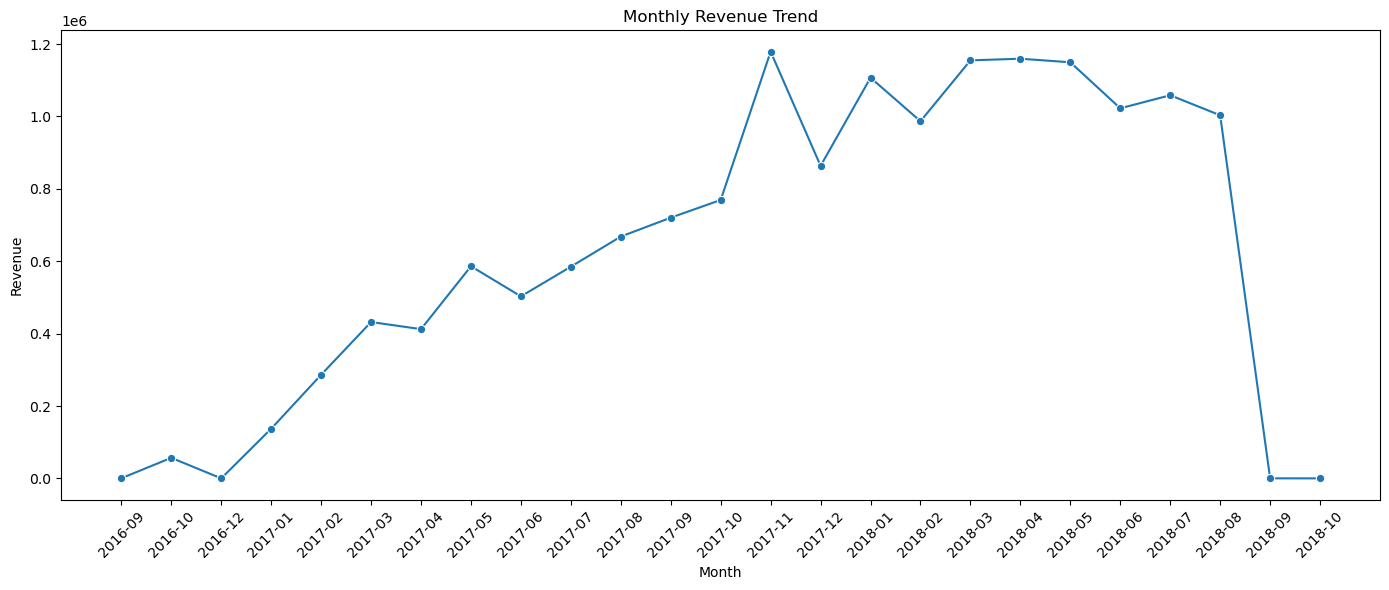

In [10]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="purchase_month",
    y="revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(PLOT_PATH + "monthly_revenue.png")

plt.show()

In [11]:
# Merge customers with orders
customer_orders = orders.merge(
    customers,
    on="customer_id",
    how="left"
)

# Unique customers
unique_customers = customers["customer_unique_id"].nunique()

# Orders per customer
customer_frequency = (
    customer_orders.groupby("customer_unique_id")["order_id"]
    .nunique()
)

repeat_customers = (customer_frequency > 1).sum()

repeat_rate = (
    repeat_customers / unique_customers * 100
    if unique_customers else 0
)

print("\n========== CUSTOMER ANALYSIS ==========")

print("Unique Customers:", unique_customers)

print("Repeat Customers:", repeat_customers)

print("Repeat Purchase Rate:", round(repeat_rate, 2), "%")

print("\nTop 10 States by Order Volume:")

print(
    customer_orders["customer_state"]
    .value_counts()
    .head(10)
)


========== CUSTOMER ANALYSIS ==========
Unique Customers: 96096
Repeat Customers: 2997
Repeat Purchase Rate: 3.12 %

Top 10 States by Order Volume:
customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64


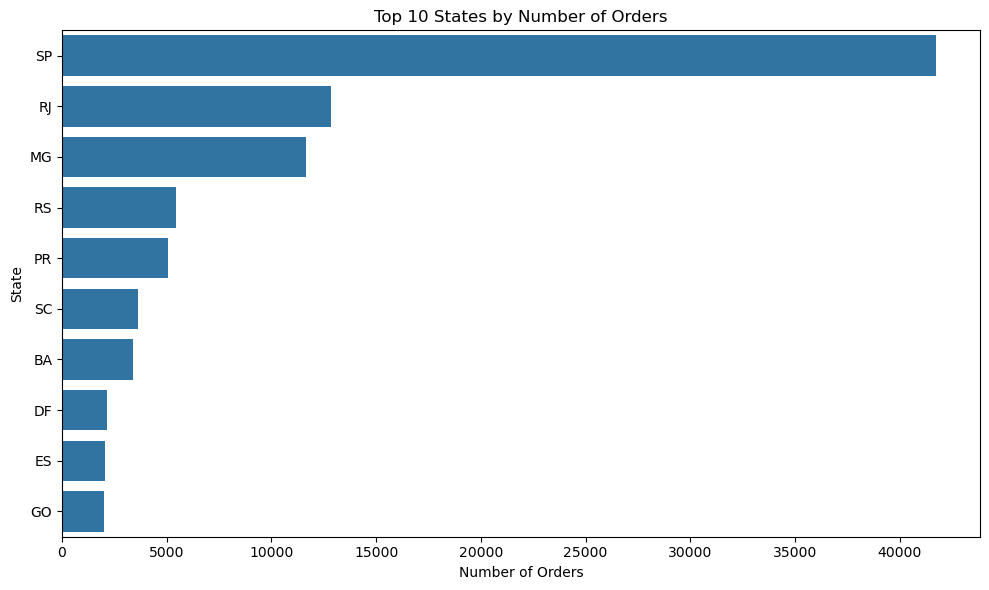

In [12]:
state_orders = (
    customer_orders["customer_state"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=state_orders.values,
    y=state_orders.index
)

plt.title("Top 10 States by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("State")

plt.tight_layout()
plt.savefig(PLOT_PATH + "customer_state_analysis.png")

plt.show()

In [13]:
product_analysis = items.merge(
    products,
    on="product_id",
    how="left"
)

category_sales = (
    product_analysis.groupby("product_category_name")
    .agg(
        revenue=("item_revenue", "sum"),
        units_sold=("order_item_id", "count")
    )
    .reset_index()
    .sort_values("revenue", ascending=False)
)

print("\n========== PRODUCT ANALYSIS ==========")

print("\nTop 10 Product Categories by Revenue:")

print(category_sales.head(10))


========== PRODUCT ANALYSIS ==========

Top 10 Product Categories by Revenue:
     product_category_name     revenue  units_sold
11            beleza_saude  1441248.07        9670
66      relogios_presentes  1305541.61        5991
13         cama_mesa_banho  1241681.72       11115
32           esporte_lazer  1156656.48        8641
44  informatica_acessorios  1059272.40        7827
54        moveis_decoracao   902511.79        8334
72   utilidades_domesticas   778397.77        6964
26              cool_stuff   719329.95        3796
8               automotivo   685384.32        4235
40      ferramentas_jardim   584219.21        4347


In [14]:
delivery = orders[
    orders["order_delivered_customer_date"].notna()
].copy()

delivery["delivery_days"] = (
    delivery["order_delivered_customer_date"] -
    delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery["is_delayed"] = (
    delivery["order_delivered_customer_date"] >
    delivery["order_estimated_delivery_date"]
)

average_delivery = delivery["delivery_days"].mean()

delayed_orders = delivery["is_delayed"].sum()

delay_percentage = (
    delayed_orders / len(delivery) * 100
    if len(delivery) else 0
)

print("\n========== DELIVERY ANALYSIS ==========")

print("Average Delivery Time:", round(average_delivery, 2), "days")

print("Delayed Orders:", delayed_orders)

print("Delayed Order Percentage:", round(delay_percentage, 2), "%")


========== DELIVERY ANALYSIS ==========
Average Delivery Time: 12.56 days
Delayed Orders: 7827
Delayed Order Percentage: 8.11 %


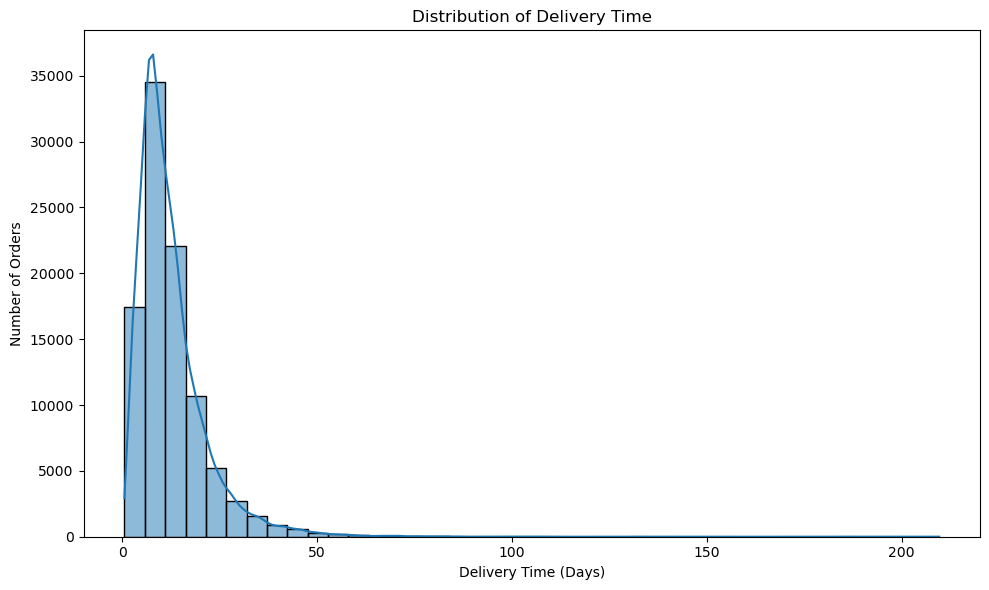

In [15]:
plt.figure(figsize=(10, 6))

sns.histplot(
    delivery["delivery_days"],
    bins=40,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.tight_layout()

plt.savefig(PLOT_PATH + "delivery_distribution.png")

plt.show()

In [16]:
print("\n========== CUSTOMER SATISFACTION ==========")

print("Average Review Score:", round(reviews["review_score"].mean(), 2))

print("\nReview Score Distribution:")

print(reviews["review_score"].value_counts().sort_index())


========== CUSTOMER SATISFACTION ==========
Average Review Score: 4.09

Review Score Distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


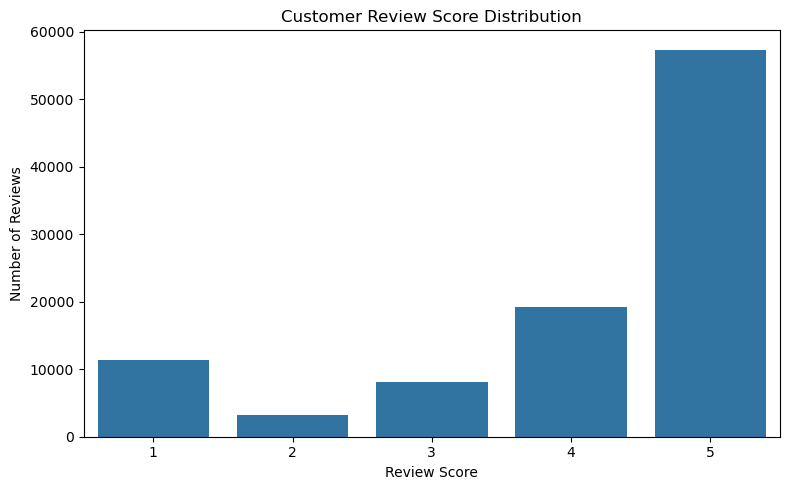

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews,
    x="review_score"
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig(PLOT_PATH + "review_distribution.png")

plt.show()

In [18]:
# Save processed analytical tables

sales.to_csv(
    OUTPUT_PATH + "sales_analysis.csv",
    index=False
)

monthly_sales.to_csv(
    OUTPUT_PATH + "monthly_sales.csv",
    index=False
)

category_sales.to_csv(
    OUTPUT_PATH + "category_analysis.csv",
    index=False
)

delivery.to_csv(
    OUTPUT_PATH + "delivery_analysis.csv",
    index=False
)

print("\nAll analytical datasets saved successfully!")


All analytical datasets saved successfully!


In [19]:
delivered_sales = sales[
    sales["order_status"] == "delivered"
]

delivered_revenue = delivered_sales["revenue"].sum()

delivered_orders = delivered_sales["order_id"].nunique()

delivered_aov = delivered_revenue / delivered_orders

print("Delivered Revenue:", round(delivered_revenue, 2))
print("Delivered Orders:", delivered_orders)
print("Delivered AOV:", round(delivered_aov, 2))

Delivered Revenue: 15419773.75
Delivered Orders: 96478
Delivered AOV: 159.83


In [20]:
category_sales["avg_revenue_per_unit"] = (
    category_sales["revenue"] /
    category_sales["units_sold"]
)

print(
    category_sales.sort_values(
        "avg_revenue_per_unit",
        ascending=False
    ).head(10)
)

                            product_category_name    revenue  units_sold  \
61                                            pcs  232799.43         203   
64                    portateis_casa_forno_e_cafe   50193.57          76   
29                             eletrodomesticos_2  123917.92         238   
0                       agro_industria_e_comercio   78374.07         212   
45                          instrumentos_musicais  210137.37         680   
31                                eletroportateis  206668.83         679   
65  portateis_cozinha_e_preparadores_de_alimentos    4278.29          15   
71                                 telefonia_fixa   64220.81         264   
25               construcao_ferramentas_seguranca   44463.62         194   
56                                  moveis_quarto   24661.01         109   

    avg_revenue_per_unit  
61           1146.795222  
64            660.441711  
29            520.663529  
0             369.689009  
45            309.025544  
3

In [21]:
monthly_sales["revenue_growth_pct"] = (
    monthly_sales["revenue"].pct_change() * 100
)

print(monthly_sales)

   purchase_month     revenue  orders  revenue_growth_pct
0         2016-09      354.75       4                 NaN
1         2016-10    56808.84     324        15913.767442
2         2016-12       19.62       1          -99.965463
3         2017-01   137188.49     800       699127.777778
4         2017-02   286280.62    1780          108.676850
5         2017-03   432048.59    2682           50.917862
6         2017-04   412422.24    2404           -4.542626
7         2017-05   586190.95    3700           42.133690
8         2017-06   502963.04    3245          -14.198089
9         2017-07   584971.62    4026           16.305091
10        2017-08   668204.60    4331           14.228550
11        2017-09   720398.91    4285            7.811127
12        2017-10   769312.37    4631            6.789774
13        2017-11  1179143.77    7544           53.272431
14        2017-12   863547.23    5673          -26.764891
15        2018-01  1107301.89    7269           28.227137
16        2018

In [4]:
pip install google-genai python-dotenv

   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.5 MB 3.3 MB/s eta 0:00:01
   ---------------------------- ----------- 1.0/1.5 MB 3.2 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 3.0 MB/s  0:00:00
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.3 MB ? eta -:--:--
   ------------- -------------------------- 0.8/2.3 MB 1.3 MB/s eta 0:00:02
   ----------------------- ---------------- 1.3/2.3 MB 1.7 MB/s eta 0:00:01
   -------------------------------- ------- 1.8/2.3 MB 1.8 MB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.3 MB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 2.3/2.3 MB 1.8 MB/s  0:00:01

  Attempting uninstall: typing-extensions

    Found existing installation: typing_extensions 4.15.0

    Uninstalling ty

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
